# Lezione 4 — Misurare il risultato: un'accuratezza del 95% è davvero buona?
**Machine Learning for the Humanities · 11 novembre**

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuri-bizzoni/yuribizzoni/blob/main/ml-humanities/lessons/04_misurare_il_risultato.ipynb)

**Laboratorio:** baseline, matrice di confusione, precision e recall. **Metodo:** primo sguardo all'apprendimento **non supervisionato**.

Nella lezione scorsa il nostro classificatore ha raggiunto il 100%. Oggi impariamo a diffidare dei numeri belli.
Il caso di studio: un **rilevatore di frasi felici**. Esistono davvero, in un romanzo, abbastanza indizi per capire dal
*contesto* che una frase parla di felicità?

### Obiettivi di apprendimento
1. calcolare e interpretare una **baseline** (il punteggio "senza intelligenza");
2. leggere una **matrice di confusione**;
3. spiegare **precision**, **recall** e **F1**, e il compromesso tra le due;
4. riconoscere quando l'accuratezza è ingannevole (classi **sbilanciate**);
5. capire la differenza tra apprendimento **supervisionato** e **non supervisionato**.

In [1]:
# ⚙️ CELLA DI PREPARAZIONE — eseguitela per prima (Shift+Invio) e non preoccupatevi del codice.
# Cerca la cartella "data" del corso; se non la trova (per esempio su Google Colab),
# scarica il materiale del corso da GitHub. Funziona anche senza internet, se avete la cartella.
from pathlib import Path
import subprocess

def trova_dati():
    for p in [Path("../data"), Path("data"), Path("ml-humanities/data"), Path("yuribizzoni/ml-humanities/data")]:
        if (p / "lessico_felicita.csv").exists():
            return p
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/yuri-bizzoni/yuribizzoni"], check=True)
    return Path("yuribizzoni/ml-humanities/data")

DATI = trova_dati()
print("Dati trovati in:", DATI.resolve())

Dati trovati in: /home/user/yuribizzoni/ml-humanities/data


## 1. Il dataset: frasi felici e frasi qualunque
Dividiamo tutti i testi del corso in frasi. Una frase è "felice" se contiene una forma delle sei famiglie (*felice, lieta, gioia,
contento…*). Poi **mascheriamo** quelle parole con `[…]`, il segno filologico dell'omissione: il modello dovrà indovinare dal contesto, senza vedere la parola stessa.

> ⚠️ Anche l'etichetta è una scelta: *"non era felice"* conta come frase felice. Le etichette costruite in automatico sono rumorose.

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, classification_report)

def leggi_testo(nome):
    righe = (DATI / "testi" / nome).read_text(encoding="utf-8").splitlines()
    return "\n".join(r for r in righe if not r.startswith("#"))

def frasi(testo, min_parole=6):
    """Divide un testo in frasi (in modo approssimativo: dopo . ! ? ;)."""
    testo = " ".join(testo.split())
    return [f for f in re.split(r"(?<=[.!?;])\s+", testo) if len(f.split()) >= min_parole]

famiglie = pd.read_csv(DATI / "famiglie_felicita_it.csv")
FORME_FELICI = set(famiglie["forma"])
MASCHERA = re.compile(r"\b(" + "|".join(sorted(FORME_FELICI, key=len, reverse=True)) + r")\b", re.IGNORECASE)

OPERE = {"collodi_pinocchio.txt": "Collodi", "manzoni_promessi_sposi.txt": "Manzoni",
         "deledda_dopo_il_divorzio.txt": "Deledda", "pirandello_cavallo_nella_luna.txt": "Pirandello",
         "digiacomo_novelle_napolitane.txt": "Di Giacomo", "dante_commedia.txt": "Dante",
         "leopardi_canti.txt": "Leopardi", "pirandello_umorismo.txt": "Pirandello (saggio)"}
righe = []
for file, autore in OPERE.items():
    for f in frasi(leggi_testo(file)):
        felice = bool(MASCHERA.search(f))
        righe.append({"autore": autore, "frase": f, "felice": int(felice),
                      "frase_mascherata": MASCHERA.sub("[…]", f)})
corpus = pd.DataFrame(righe)
print(len(corpus), "frasi;", corpus["felice"].sum(), "contengono una parola felice")

29040 frasi; 630 contengono una parola felice


In [3]:
corpus.sample(5, random_state=1)[["autore", "felice", "frase_mascherata"]]

,autore,felice,frase_mascherata
25367,Dante,0,"Ond’ io: «Sì ho, sì lucida e sì tonda, che nel..."
12084,Deledda,0,"Ecco, Costantino restò sotto la sua tutela;"
6714,Manzoni,0,«Dov'è andato?» «A Rimini.» «A?» «A Rimini.» «...
8849,Manzoni,0,"e se, interrogato di ciò, come forse vi ricord..."
9336,Manzoni,0,Il territorio bergamasco non era tanto distant...


In [4]:
print(f"Percentuale di frasi felici: {corpus['felice'].mean():.1%}")

Percentuale di frasi felici: 2.2%


## 2. La baseline: il punteggio del pigro
Una **baseline** è il risultato di una strategia stupida. Qui la strategia più stupida è rispondere sempre **"non felice"**.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    corpus["frase_mascherata"], corpus["felice"], test_size=0.25, random_state=0, stratify=corpus["felice"])

pigro = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Accuratezza del classificatore pigro: {pigro.score(X_test, y_test):.1%}")
print("Frasi felici trovate:", pigro.predict(X_test).sum(), "su", y_test.sum())

Accuratezza del classificatore pigro: 97.8%
Frasi felici trovate: 0 su 157


**Un'accuratezza del 98% che non trova nemmeno una frase felice.** Quando una classe è rara, l'accuratezza è quasi inutile:
il numero da battere non è 50%, è la baseline.

## 3. Un classificatore vero

In [6]:
modello = make_pipeline(TfidfVectorizer(min_df=2), LogisticRegression(max_iter=1000))
modello.fit(X_train, y_train)
pred = modello.predict(X_test)
print(f"Accuratezza: {accuracy_score(y_test, pred):.1%}")
print("Frasi felici trovate:", pred.sum(), "su", y_test.sum())

Accuratezza: 97.8%
Frasi felici trovate: 0 su 157


## 4. La matrice di confusione
Mette a confronto la **verità** (righe) con le **previsioni** (colonne):

| | previsto: no | previsto: sì |
|---|---|---|
| **vero: no** | veri negativi (VN) | falsi positivi (FP) |
| **vero: sì** | falsi negativi (FN) | veri positivi (VP) |

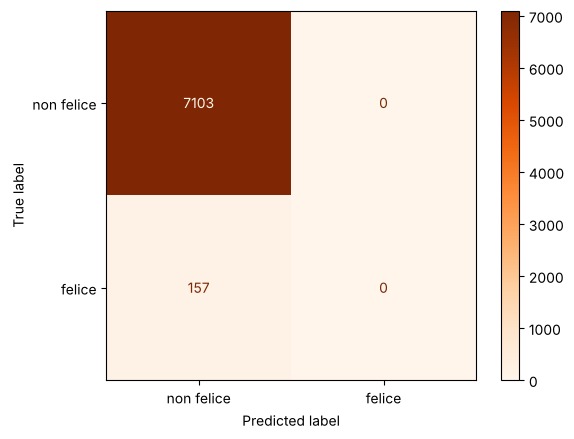

In [7]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["non felice", "felice"], cmap="Oranges")
plt.show()

## 5. Precision e recall
Pensate a un archivio: cercate le lettere che parlano di felicità.
- **Precision** = di ciò che ho trovato, quanto è giusto? $\;VP / (VP + FP)$
- **Recall** (richiamo) = di ciò che c'era da trovare, quanto ho trovato? $\;VP / (VP + FN)$
- **F1** = una media (armonica) delle due: è alta solo se lo sono entrambe.

Un motore di ricerca molto prudente ha precision alta e recall bassa; uno che restituisce tutto ha recall alta e precision bassa.

In [8]:
print(f"precision: {precision_score(y_test, pred, zero_division=0):.2f}")
print(f"recall:    {recall_score(y_test, pred):.2f}")
print(f"F1:        {f1_score(y_test, pred):.2f}")

precision: 0.00
recall:    0.00
F1:        0.00


**Il modello si comporta esattamente come il pigro**: non dice mai *felice*. Con il 2% di positivi, il modo più sicuro
di sbagliare poco è non rischiare mai. L'accuratezza non se ne accorge; la recall sì.

Possiamo dire all'algoritmo che la classe rara conta di più (`class_weight="balanced"`).

accuratezza 93.2% | precision 0.09 | recall 0.24 | F1 0.13


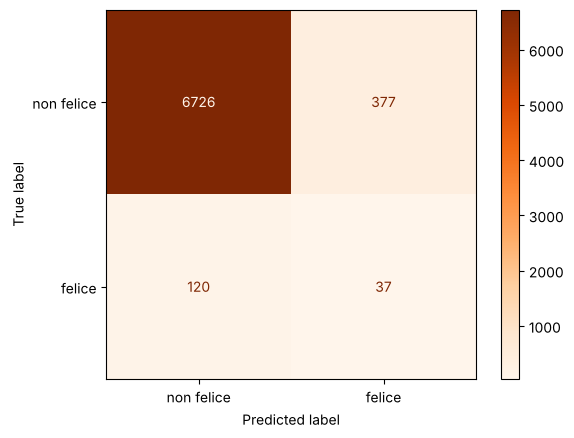

In [9]:
bilanciato = make_pipeline(TfidfVectorizer(min_df=2), LogisticRegression(max_iter=1000, class_weight="balanced"))
bilanciato.fit(X_train, y_train)
pred_b = bilanciato.predict(X_test)
print(f"accuratezza {accuracy_score(y_test, pred_b):.1%} | precision {precision_score(y_test, pred_b):.2f} | "
      f"recall {recall_score(y_test, pred_b):.2f} | F1 {f1_score(y_test, pred_b):.2f}")
ConfusionMatrixDisplay.from_predictions(y_test, pred_b, display_labels=["non felice", "felice"], cmap="Oranges")
plt.show()

**L'accuratezza è scesa, ma il modello è più utile**: ora trova una parte delle frasi felici, al prezzo di molti falsi allarmi
(precision bassa). È un risultato onesto: **il contesto, da solo, dice poco** sulla felicità di una frase.
Quale errore è peggiore dipende dallo scopo: per *esplorare* un archivio conviene una recall alta (poi leggiamo noi);
per *contare* con precisione serve una precision alta.

> 🕵️ **Una storia vera (di questo notebook).** In una prima versione mascheravamo le parole felici con `___`. Risultato: 100%
> di accuratezza! Il motivo: per il vettorizzatore `___` era una "parola", e compariva solo nelle frasi felici. Il modello aveva
> imparato la nostra maschera, non la felicità. Si chiama **data leakage** (fuga di informazione): quando un risultato è troppo
> bello, cercate da dove il modello "sbircia" la risposta.

### Il compromesso, al variare della soglia
La regressione logistica dà una probabilità; di solito si dice "sì" sopra 0,5. Spostando la soglia scegliamo il compromesso.

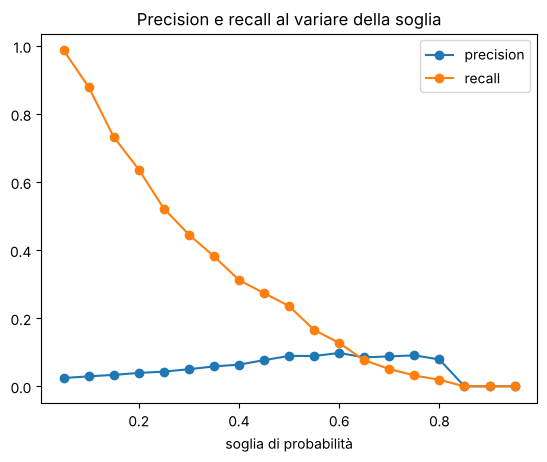

In [10]:
prob = bilanciato.predict_proba(X_test)[:, 1]
soglie = np.linspace(0.05, 0.95, 19)
prec = [precision_score(y_test, prob >= s, zero_division=0) for s in soglie]
rec = [recall_score(y_test, prob >= s) for s in soglie]
plt.plot(soglie, prec, "o-", label="precision")
plt.plot(soglie, rec, "o-", label="recall")
plt.xlabel("soglia di probabilità"); plt.legend(); plt.title("Precision e recall al variare della soglia"); plt.show()

### Che cosa ha imparato a riconoscere?

In [11]:
vocab = bilanciato.named_steps["tfidfvectorizer"].get_feature_names_out()
pesi = bilanciato.named_steps["logisticregression"].coef_[0]
print("Indizi di felicità:", ", ".join(vocab[np.argsort(pesi)[-20:][::-1]]))

Indizi di felicità: staremo, ben, esser, vedervi, dì, prole, mira, sentì, saltò, condannato, saltando, esto, state, sazio, sorrise, la, onde, uomo, resero, oibò


Tra gli indizi ci sono parole sensate (*sorrise, saltando, sazio, ben*) accanto a parole casuali, che compaiono in poche
frasi felici del training per pura coincidenza. Con pochi esempi positivi (circa 470) il modello impara un po' di **collocazioni**
della felicità e molto **rumore**. Le parole che stanno *accanto* alla felicità saranno il tema della *semantica distribuzionale* (18 novembre).

## 6. Più di due classi: chi ha scritto questa frase?
Torniamo all'attribuzione d'autore, ma con **frasi singole** invece di brani di 200 parole. Il compito diventa molto più difficile.

Accuratezza su frasi singole: 65.9%  (baseline: 20%)


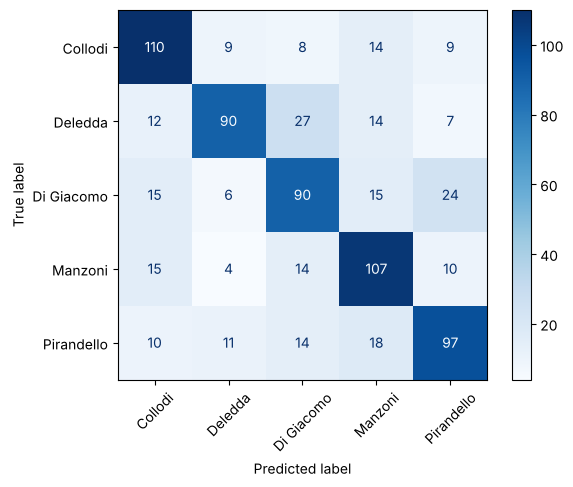

In [12]:
prosa = corpus[corpus["autore"].isin(["Collodi", "Manzoni", "Deledda", "Pirandello", "Di Giacomo"])]
campione = prosa.groupby("autore").sample(600, random_state=0)
Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    campione["frase"], campione["autore"], test_size=0.25, random_state=0, stratify=campione["autore"])

svm = make_pipeline(TfidfVectorizer(), LinearSVC()).fit(Xa_train, ya_train)
pred_a = svm.predict(Xa_test)
print(f"Accuratezza su frasi singole: {accuracy_score(ya_test, pred_a):.1%}  (baseline: 20%)")
ConfusionMatrixDisplay.from_predictions(ya_test, pred_a, cmap="Blues", xticks_rotation=45)
plt.show()

In [13]:
print(classification_report(ya_test, pred_a))

              precision    recall  f1-score   support

     Collodi       0.68      0.73      0.71       150
     Deledda       0.75      0.60      0.67       150
  Di Giacomo       0.59      0.60      0.59       150
     Manzoni       0.64      0.71      0.67       150
  Pirandello       0.66      0.65      0.65       150

    accuracy                           0.66       750
   macro avg       0.66      0.66      0.66       750
weighted avg       0.66      0.66      0.66       750



La matrice dice **chi viene confuso con chi**: un'informazione molto più interessante, per un umanista, di un singolo numero.

## 7. E se non avessimo etichette? L'apprendimento non supervisionato
Finora abbiamo sempre dato al modello la risposta giusta (**supervisionato**). Nell'apprendimento **non supervisionato**
il modello riceve solo i dati e cerca da solo una **struttura**: gruppi, dimensioni, somiglianze.

Un primo strumento: la **PCA** (analisi delle componenti principali) riassume migliaia di colonne TF-IDF in due sole
dimensioni, per poter *disegnare* i testi. Il modello non sa nulla degli autori: i colori li aggiungiamo **dopo**.

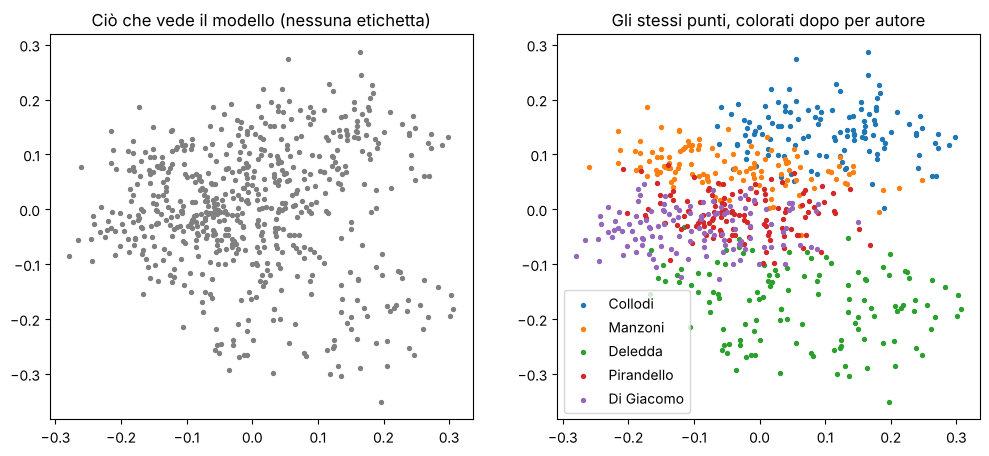

In [14]:
from sklearn.decomposition import PCA

passaggi = pd.read_csv(DATI / "passaggi_autori.csv")
X_tfidf = TfidfVectorizer(max_features=2000).fit_transform(passaggi["testo"]).toarray()
coordinate = PCA(n_components=2, random_state=0).fit_transform(X_tfidf)

fig, assi = plt.subplots(1, 2, figsize=(12, 5))
assi[0].scatter(coordinate[:, 0], coordinate[:, 1], s=8, color="gray")
assi[0].set_title("Ciò che vede il modello (nessuna etichetta)")
for autore in passaggi["autore"].unique():
    m = (passaggi["autore"] == autore).to_numpy()
    assi[1].scatter(coordinate[m, 0], coordinate[m, 1], s=8, label=autore)
assi[1].legend(); assi[1].set_title("Gli stessi punti, colorati dopo per autore")
plt.show()

Già nella nuvola grigia si intravedono gruppi. Nella prossima lezione un algoritmo (**k-means**) proverà a trovarli da solo.

## Riepilogo
- Confrontate sempre con una **baseline**.
- Con classi sbilanciate l'**accuratezza inganna**: guardate **precision**, **recall**, **F1** e la **matrice di confusione**.
- La **soglia** e i **pesi delle classi** spostano il compromesso tra trovare tutto e sbagliare poco.
- **Supervisionato** = con risposte giuste; **non supervisionato** = cercare struttura senza etichette.

## Esercizi
Soluzioni in `solutions/04_misurare_il_risultato_soluzioni.ipynb`.

**Esercizio 1 — A mano.** Un collega dichiara: "Il mio rilevatore di ironia ha il 95% di accuratezza". Su 1000 frasi, 50 sono
ironiche; il rilevatore ne segnala 30, di cui 20 davvero ironiche. Calcolate VP, FP, FN, VN, accuratezza, precision, recall e F1.
È un buon rilevatore?

**Esercizio 2 — Leggere gli errori.** Con il modello `bilanciato`, mostrate 8 **falsi positivi** (frasi segnalate come felici ma
senza parole felici). Leggetele: sono davvero frasi "non felici"? Che cosa ci dice questo sulle nostre etichette?

**Esercizio 3 — Quale autore è più difficile?** Per il compito su frasi singole calcolate le baseline `most_frequent` e
`stratified` e la recall di ciascun autore. Quale autore il modello riconosce meno bene? Avete un'ipotesi letteraria sul perché?

In [15]:
# Esercizio 1

In [16]:
# Esercizio 2

In [17]:
# Esercizio 3